In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("noisy_curvefit_data.csv")

In [3]:
df.shape

(100, 6)

In [4]:
# 100 rows, 6 columns

In [5]:
print(df.head(5))
print(df.tail(5))

          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


In [6]:
# columns names are x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, and y_noise_5

<function matplotlib.pyplot.show(close=None, block=None)>

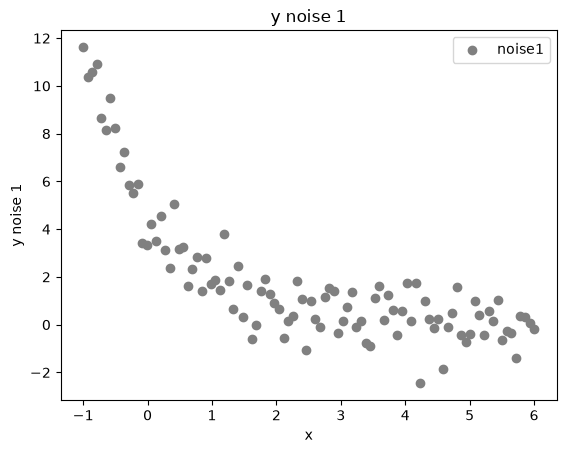

In [7]:
plt.figure()
plt.scatter(df["x"], df["y_noise_1"], color="Gray", label="noise1")
plt.xlabel("x")
plt.ylabel("y noise 1")
plt.title("y noise 1")
plt.legend()
plt.show


In [8]:
def model(x, A, k):
    return A * np.exp(-k*x)

In [9]:
p0 = [1,1]

In [10]:
popt, pcov = curve_fit(model, df["x"], df["y_noise_1"], p0=p0)

In [11]:
A_fit, k_fit, = popt

In [12]:
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

Fit: y = 4.71 * e^(-0.92 * x)


In [13]:
residuals = df["y_noise_1"] - model(df["x"], A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(df["x"]) - len(popt)
chi2_reduced = chi2 / dof
print(chi2_reduced)

0.7906732087457313


<function matplotlib.pyplot.show(close=None, block=None)>

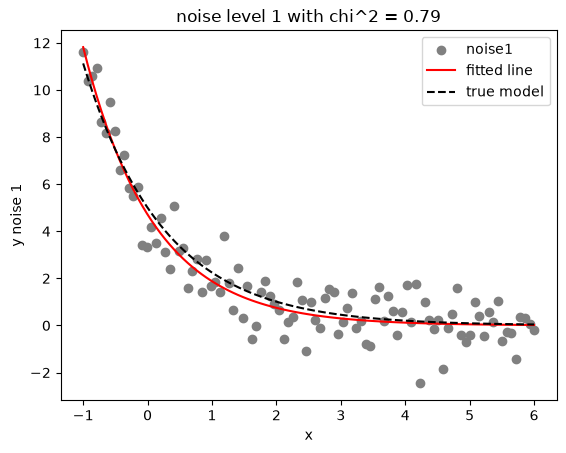

In [14]:
#scatter the noisy data
plt.figure()
plt.scatter(df["x"], df["y_noise_1"], color="Gray", label="noise1")

#plot fitted line
plt.plot(df["x"], 4.71 * np.exp(-0.92 * df["x"]), color = "Red", label="fitted line")

#plot true model
plt.plot(df["x"], model(df["x"], 5, 0.8), color="Black", linestyle="--", label="true model")

plt.xlabel("x")
plt.ylabel("y noise 1")
plt.title("noise level 1 with chi^2 = 0.79")
plt.legend()
plt.show